Mini-Batch GD + Momentum -> Test MSE: 331.46 | R2: 0.3588


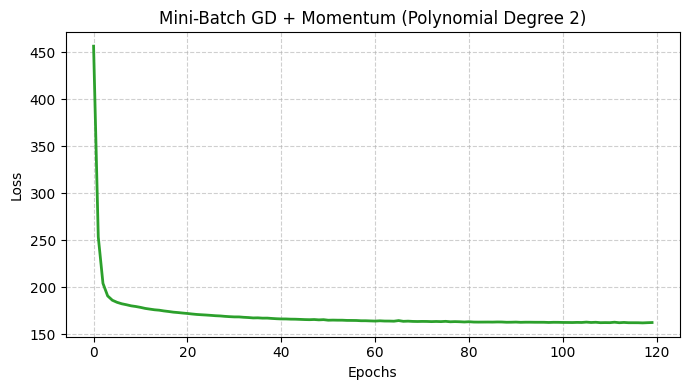

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

CSV_PATH = "/kaggle/input/datasets/alimohammad4434/123data/diabetes_prediction_dataset.csv"
TARGET_COL = "age"

df = pd.read_csv(CSV_PATH).dropna(subset=[TARGET_COL]).copy()
df = df.sample(n=min(5000, len(df)), random_state=42)

X_df = pd.get_dummies(df.drop(columns=[TARGET_COL]), drop_first=True)
X_df = X_df.fillna(X_df.median(numeric_only=True))
y = df[TARGET_COL].to_numpy(dtype=np.float64).reshape(-1, 1)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_df.to_numpy(dtype=np.float64), y, test_size=0.2, random_state=42
)

poly = PolynomialFeatures(degree=2, include_bias=False)
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(poly.fit_transform(X_train_raw))
X_test_scaled = scaler.transform(poly.transform(X_test_raw))

X_train = np.c_[np.ones((X_train_scaled.shape[0], 1)), X_train_scaled]
X_test = np.c_[np.ones((X_test_scaled.shape[0], 1)), X_test_scaled]

# تدريب Mini-Batch GD + Momentum
lr = 0.01
beta1 = 0.9
batch_size = 64
epochs = 120
n_samples = len(y_train)

np.random.seed(42)
theta = np.random.randn(X_train.shape[1], 1) * 0.01
v = np.zeros_like(theta)
losses = []

for _ in range(epochs):
    indices = np.random.permutation(n_samples)
    X_shuf = X_train[indices]
    y_shuf = y_train[indices]
    for i in range(0, n_samples, batch_size):
        xb = X_shuf[i:i+batch_size]
        yb = y_shuf[i:i+batch_size]
        grad = (1 / len(yb)) * (xb.T @ ((xb @ theta) - yb))
        v = beta1 * v + (1 - beta1) * grad
        theta -= lr * v
    losses.append((1 / (2 * n_samples)) * np.sum(((X_train @ theta) - y_train) ** 2))

y_pred = X_test @ theta
print(f"Mini-Batch GD + Momentum -> Test MSE: {mean_squared_error(y_test, y_pred):.2f} | R2: {r2_score(y_test, y_pred):.4f}")

plt.figure(figsize=(7, 4))
plt.plot(losses, color="#2ca02c", linewidth=2)
plt.title("Mini-Batch GD + Momentum (Polynomial Degree 2)")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()